# Análisis exploratorio de las exportaciones vitivinícolas

Este notebook trabaja sobre la base `data/exportaciones_vino.db` que genera `python src/main.py`.
Reutiliza las mismas clases y consultas del proyecto (`src/`) para explorar los resultados de forma interactiva.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Raíz del proyecto (este notebook está en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RAIZ / "src"))

import consultas
from analisis import AnalizadorExportaciones

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
conexion = sqlite3.connect(RAIZ / "data" / "exportaciones_vino.db")

## 1. Tablas de la base de datos

In [2]:
tablas = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table' AND name <> 'sqlite_sequence'", conexion)
tablas["filas"] = [pd.read_sql_query(f"SELECT COUNT(*) AS n FROM {t}", conexion)["n"][0] for t in tablas["name"]]
tablas

,name,filas
0,paises,109
1,productos,84
2,variedades,54
3,exportaciones,22520
4,analisis_destinos,149


## 2. Consulta SQL (JOIN + GROUP BY) capturada en un DataFrame

In [3]:
resumen = pd.read_sql_query(consultas.RESUMEN_POR_DESTINO, conexion)
resumen.head(10)

,pais,region,modalidad_envio,operaciones,productos_distintos,litros_totales,fob_total_usd,litros_promedio_operacion
0,Estados Unidos,Norteamérica,fraccionado,4636,46,"12,046,530.00","56,568,326.84","2,598.47"
1,Brasil,Latinoamérica y Caribe,fraccionado,3220,43,"6,806,837.00","25,310,992.20","2,113.92"
2,Reino Unido,Europa,fraccionado,1408,32,"4,873,741.00","18,468,103.85","3,461.46"
3,Canada,Norteamérica,fraccionado,1369,24,"2,694,590.00","12,190,061.89","1,968.29"
4,Estados Unidos,Norteamérica,granel,174,10,"5,820,971.00","11,483,443.82","33,453.86"
5,Reino Unido,Europa,granel,299,7,"9,299,900.00","10,012,809.86","31,103.34"
6,Mexico,Norteamérica,fraccionado,575,31,"1,717,898.00","6,184,456.24","2,987.65"
7,Japon,Asia y Medio Oriente,granel,66,5,"2,488,126.00","5,600,974.27","37,698.88"
8,Paises Bajos,Europa,fraccionado,873,27,"1,486,090.00","5,510,506.45","1,702.28"
9,Peru,Latinoamérica y Caribe,fraccionado,1077,40,"1,012,899.00","4,468,742.31",940.48


## 3. Columnas calculadas y mercados de fraccionado con precio sobre el promedio

In [4]:
analizador = AnalizadorExportaciones(resumen).agregar_columnas()
premium = analizador.mercados_premium_fraccionado(minimo_operaciones=10)
premium[["pais", "region", "operaciones", "litros_totales", "fob_total_usd", "usd_por_litro", "segmento_precio"]].head(10)


[Análisis] Columnas nuevas creadas: usd_por_litro, participacion_fob_pct, participacion_litros_pct, fob_promedio_operacion, segmento_precio, ranking_fob

[Análisis] Precio promedio del fraccionado: 4.83 USD/l
[Análisis] Mercados de fraccionado con precio sobre el promedio y >= 10 operaciones: 39


,pais,region,operaciones,litros_totales,fob_total_usd,usd_por_litro,segmento_precio
84,Rumania,Europa,18,"8,181.00","127,343.96",15.57,Alto (>5)
91,Eslovaquia,Europa,21,"10,659.00","105,234.72",9.87,Alto (>5)
82,Grecia,Europa,48,"15,936.00","136,745.17",8.58,Alto (>5)
66,Terr.Vinculados Al Reino Unido,Otros,83,"30,703.00","249,614.17",8.13,Alto (>5)
48,Hong Kong Reg.Admin.Espec.De(China),Asia y Medio Oriente,241,"73,937.00","588,949.40",7.97,Alto (>5)
20,Panama,Latinoamérica y Caribe,466,"290,029.00","2,299,854.51",7.93,Alto (>5)
68,Curazao,Latinoamérica y Caribe,81,"29,140.00","214,474.13",7.36,Alto (>5)
94,Nigeria,África,26,"13,063.00","95,048.04",7.28,Alto (>5)
96,Barbados,Latinoamérica y Caribe,25,"11,692.00","84,867.87",7.26,Alto (>5)
40,Dinamarca,Europa,116,"118,014.00","773,816.00",6.56,Alto (>5)


## 4. Fraccionado vs. granel por región

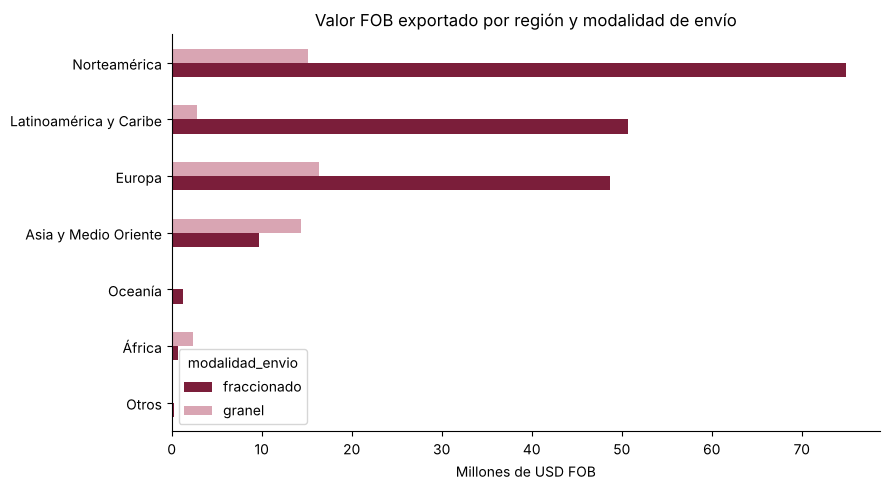

In [5]:
por_region = analizador.resumen_por_region()
tabla = por_region.pivot(index="region", columns="modalidad_envio", values="fob_usd").fillna(0) / 1_000_000
tabla = tabla.sort_values("fraccionado")

ax = tabla.plot.barh(figsize=(9, 5), color={"fraccionado": "#7b1e3a", "granel": "#d9a5b3"})
ax.set_xlabel("Millones de USD FOB")
ax.set_ylabel("")
ax.set_title("Valor FOB exportado por región y modalidad de envío")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. Ranking de variedades (vino fraccionado)

In [6]:
pd.read_sql_query(consultas.RANKING_VARIEDADES, conexion)

,variedad,color,operaciones,paises_destino,litros_totales,fob_total_usd,usd_por_litro
0,Malbec,tinto,9640,102,"24,884,867.00","110,737,159.76",4.45
1,Cabernet Sauvignon,tinto,2847,97,"4,800,281.00","21,270,981.31",4.43
2,Chardonnay,blanco,1907,91,"2,657,163.00","10,956,421.30",4.12
3,Cabernet Franc,tinto,798,66,"504,094.00","3,520,030.65",6.98
4,Torrontes Riojano,blanco,662,58,"892,647.00","3,290,247.97",3.69
5,Pinot Negro,tinto,522,51,"470,094.00","3,086,906.28",6.57
6,Sauvignon Blanc,blanco,579,66,"726,626.00","2,511,728.06",3.46
7,Pinot Gris,blanco,246,41,"519,918.00","1,782,022.42",3.43
8,Malbec,rosado,297,43,"443,596.00","1,572,493.27",3.54
9,Syrah,tinto,276,39,"374,951.00","1,362,972.77",3.64


In [7]:
conexion.close()